In [1]:
# 그래프관련 import 
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False

# 프로그램 
import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier # 분류 클래스
from sklearn.neighbors import KNeighborsRegressor # 예측 클래스
from sklearn.linear_model import LinearRegression # 예측 클래스
from sklearn.metrics import mean_absolute_error # 평균절대오차 오차범위 클래스
from sklearn.preprocessing import StandardScaler  # 정규화 클래스
from sklearn.model_selection import train_test_split

In [2]:
perch_length = np.array(
    [8.4, 13.7, 15.0, 16.2, 17.4, 18.0, 18.7, 19.0, 19.6, 20.0,
     21.0, 21.0, 21.0, 21.3, 22.0, 22.0, 22.0, 22.0, 22.0, 22.5,
     22.5, 22.7, 23.0, 23.5, 24.0, 24.0, 24.6, 25.0, 25.6, 26.5,
     27.3, 27.5, 27.5, 27.5, 28.0, 28.7, 30.0, 32.8, 34.5, 35.0,
     36.5, 36.0, 37.0, 37.0, 39.0, 39.0, 39.0, 40.0, 40.0, 40.0,
     40.0, 42.0, 43.0, 43.0, 43.5, 44.0]
     )
perch_weight = np.array(
    [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
     110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
     130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
     197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
     514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
     820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
     1000.0, 1000.0]
     )

In [ ]:
# 훈련데이터, 테스트데이터 분리 
train_data,test_data,train_label,test_label = train_test_split(perch_length,perch_weight)

# 훈련데이터는 2차원 데이터가 되어야함
train_data

array([22.7, 27.5, 43. , 35. , 23. , 27.5, 37. , 21. , 42. , 22.5, 25. ,
       16.2, 21. , 37. , 27.3, 40. , 36. , 24. , 36.5, 44. , 40. , 39. ,
       27.5, 18. , 22. ,  8.4, 24. , 22. , 25.6, 21. , 28.7, 40. , 34.5,
       22. , 19.6, 32.8, 22. , 21.3, 39. , 40. , 18.7, 17.4])

In [5]:
# 훈련데이터 2차원배열 변경 
train_data = train_data.reshape(-1,1)
train_data[:5]
test_data = test_data.reshape(-1,1)
test_data[:5]

array([[15. ],
       [23.5],
       [22.5],
       [24.6],
       [39. ]])

In [6]:
# 데이터 학습
lr = LinearRegression()
# 선형회귀
lr.fit(train_data,train_label)

# 데이터 예측 
predict = lr.predict(test_data)
print('예측 무게 :', predict)

# 정확도
score = lr.score(train_data,train_label)
score2 = lr.score(test_data,test_label)
print('train 정확도 :', score)
print('test 정확도 :', score2)


예측 무게 : [ -91.76986883  220.36693582  183.6449588   260.76111054  789.55757959
  385.6158324    91.84001626  330.53286687  954.80647617  936.44548766
   55.11803924  459.05978644 -139.50843895  165.2839703 ]
train 정확도 : 0.9191725792889918
test 정확도 : 0.9162978095876992


In [8]:
print(lr.coef_,lr.intercept_)

[36.72197702] -642.5995240870448


In [9]:
print(lr.coef_)

[36.72197702]


In [16]:
in_data = input('농어 길이를 입력하세요. >>')
in_data = float(in_data)
result = lr.predict([[in_data]])
print(f'농어예측무게 :, {result[0]}g')

# result = lr.predict([[27]])
# result

농어예측무게 :, 642.6696715225517g


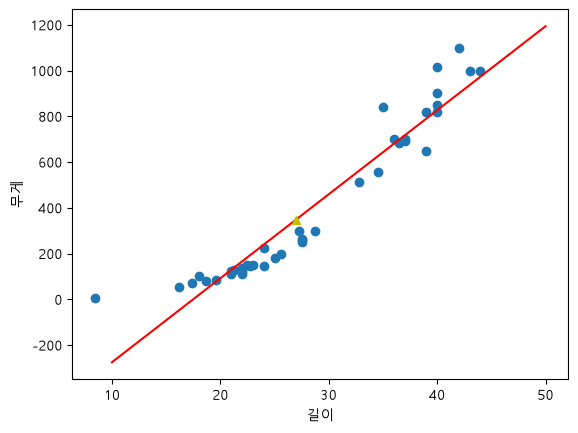

In [14]:
# 산점그래프
plt.scatter(train_data,train_label)
plt.plot([10,50],[10*lr.coef_+lr.intercept_,50*lr.coef_+lr.intercept_],color='r')
plt.plot(27,348,marker="^",color="y")
# plt.plot(point,lr.coef_[0]*point**2+lr.coef_[1]*point+lr.intercept_)
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()